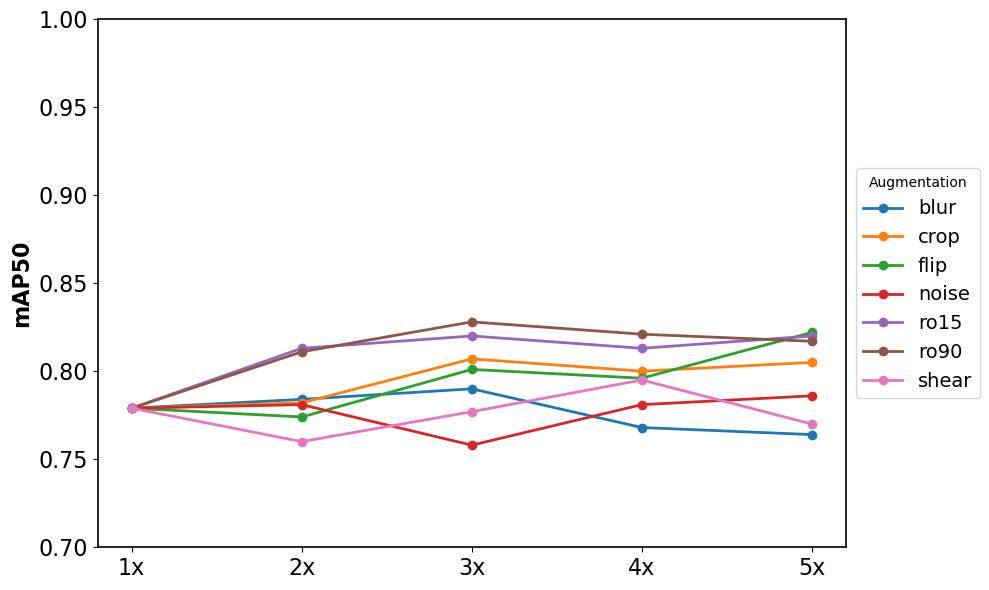

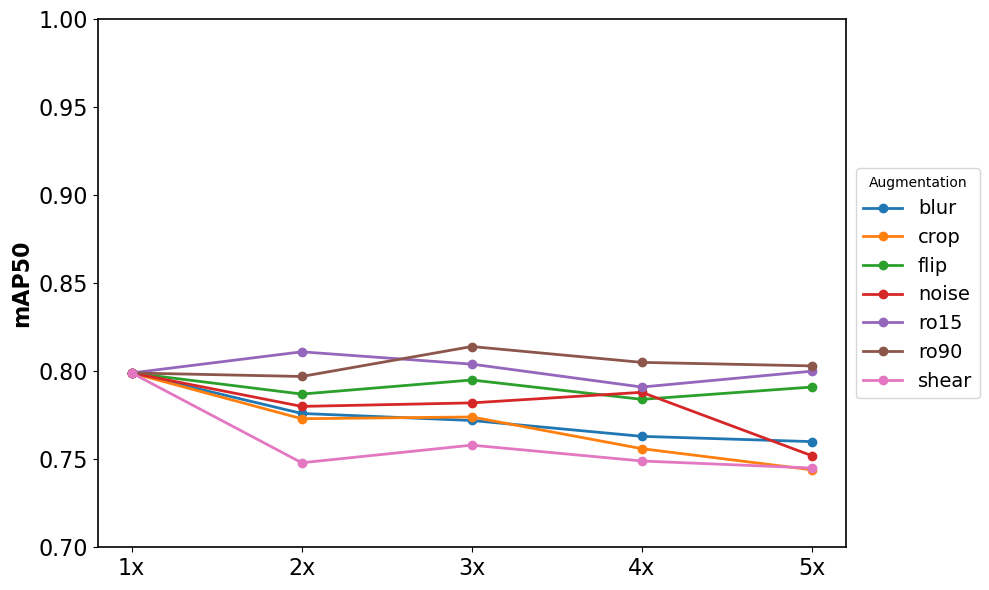

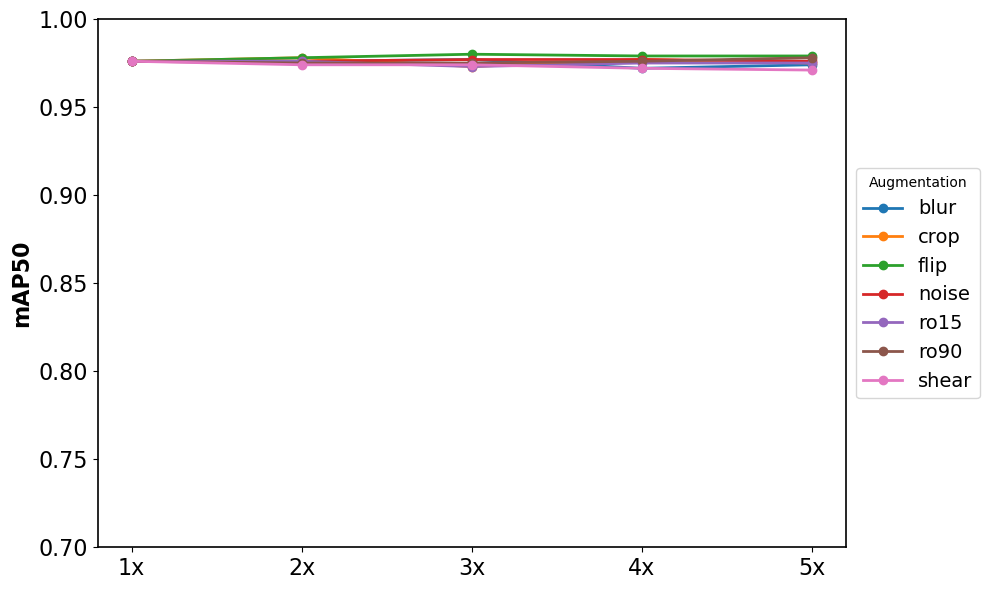

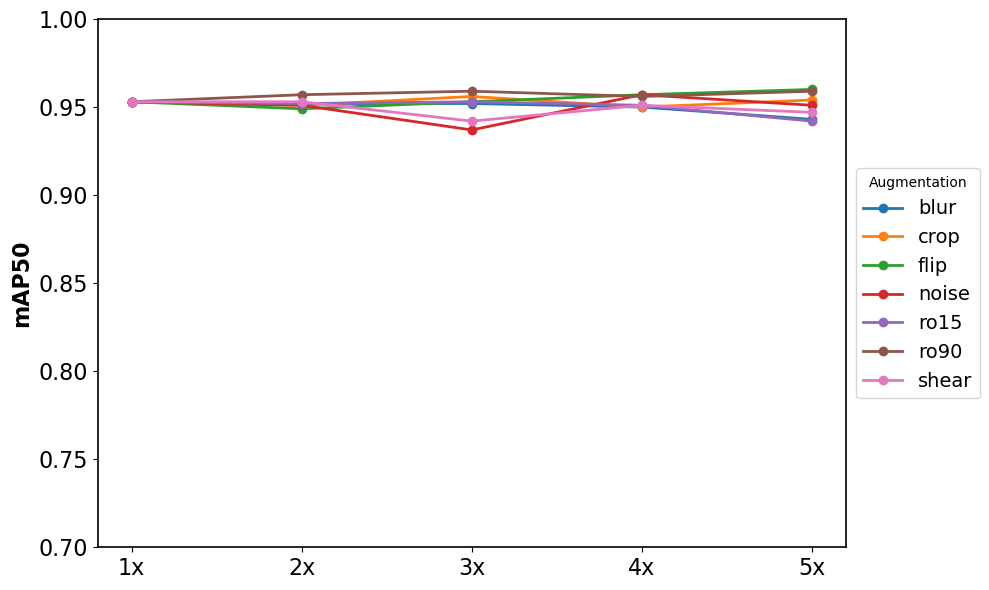

In [13]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt

# 1. CSV 파일들이 있는 폴더 경로 지정 (실제 폴더 경로로 수정해주세요!)
# 예: './augmentation_csv_results'
folder_path = 'C:/Users/ACE_LAB_AI/Desktop/object_detection_cell/full_data_1com_aug1to5' 

# 폴더 내의 모든 csv 파일 경로 가져오기
csv_files = glob.glob(os.path.join(folder_path, '*.csv'))

# 데이터를 하나로 모을 리스트
all_data = []

# 2. 모든 CSV 파일 읽어서 데이터 통합하기
for file in csv_files:
    # 파일명에서 증강 기법과 배수 추출 (예: 'blur_2_data.csv' -> 'blur', 2)
    filename = os.path.basename(file)
    parts = filename.split('_')
    
    aug_method = parts[0]       # 증강 기법 (blur, crop, flip 등)
    multiplier = int(parts[1])  # 배수 (2, 3, 4, 5)
    
    # CSV 읽기
    df = pd.read_csv(file)
    
    # 각 클래스의 mAP50 데이터 추출하여 리스트에 추가
    for index, row in df.iterrows():
        # 'all' 클래스는 제외하고 개별 클래스(E, L, M, N)만 타겟팅
        if row['Class'] in ['E', 'L', 'M', 'N']:
            all_data.append({
                'Class': row['Class'],
                'Augmentation': aug_method,
                'Multiplier': multiplier,
                'mAP50': row['mAP50']
            })

# 리스트를 하나의 데이터프레임으로 변환
merged_df = pd.DataFrame(all_data)

# 3. 클래스별로 4개의 그래프 그리기
target_classes = ['E', 'L', 'M', 'N']

# 한글 폰트 설정 및 그래프 스타일 (선택 사항)
plt.style.use('default') 

for cls in target_classes:
    # 도화지 생성 및 배경 흰색 설정
    fig = plt.figure(figsize=(10, 6))
    fig.patch.set_facecolor('white')
    
    # 현재 그래프 영역(ax) 가져오기 및 배경 흰색 설정
    ax = plt.gca()
    ax.set_facecolor('white')
    
    # 사방에 검은색 테두리 그리기
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(1.2)
        spine.set_visible(True)
    
    # 현재 클래스 데이터만 필터링
    cls_data = merged_df[merged_df['Class'] == cls]
    
    # 증강 기법별로 라인 그래프 그리기 (총 7개 라인)
    aug_methods = cls_data['Augmentation'].unique()
    
    for aug in aug_methods:
        # 특정 증강 기법 데이터만 뽑아서 배수(x축) 순서대로 정렬
        aug_data = cls_data[cls_data['Augmentation'] == aug].sort_values(by='Multiplier')
        
        plt.plot(aug_data['Multiplier'], aug_data['mAP50'], marker='o', label=aug, linewidth=2)
    
    # 그래프 꾸미기
    #plt.title(f'mAP50 by Augmentation Methods - Class [{cls}]', fontsize=16, fontweight='bold')
    #plt.xlabel('Augmentation Multiplier (2x ~ 5x)', fontsize=12)
    plt.ylabel('mAP50', fontsize=16, fontweight='bold')
    
    plt.ylim(0.7, 1.0)
    plt.yticks(fontsize=16) 

    # x축 눈금 확실하게 2, 3, 4, 5로 고정
    labels = ['1x', '2x', '3x', '4x','5x']
    plt.xticks([1, 2, 3, 4, 5], labels, fontsize=16) 
    
    # 범례 표시 (그래프 밖으로 빼려면 bbox_to_anchor 사용)
    plt.legend(title='Augmentation', loc='center left', bbox_to_anchor=(1, 0.5), fontsize=14)
    
    # 레이아웃 조정
    plt.tight_layout()
    
    # 1. 먼저 파일로 저장! (bbox_inches='tight'를 넣으면 범례가 잘리지 않아요)
    plt.savefig(f'paper_figure/figure2_{cls}.png', dpi=300, bbox_inches='tight')
    
    # 2. 그 다음에 화면에 출력!
    plt.show()

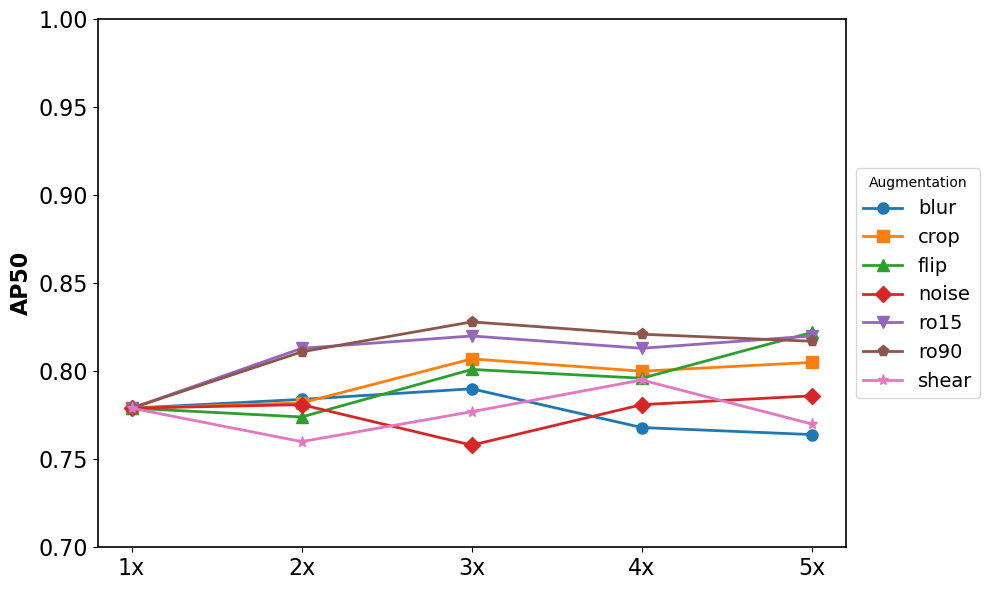

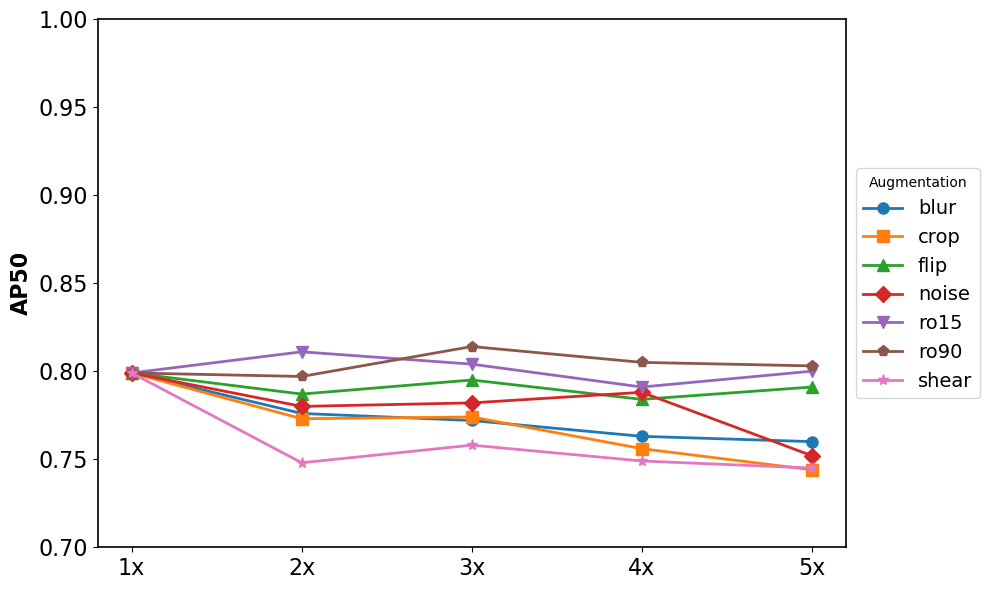

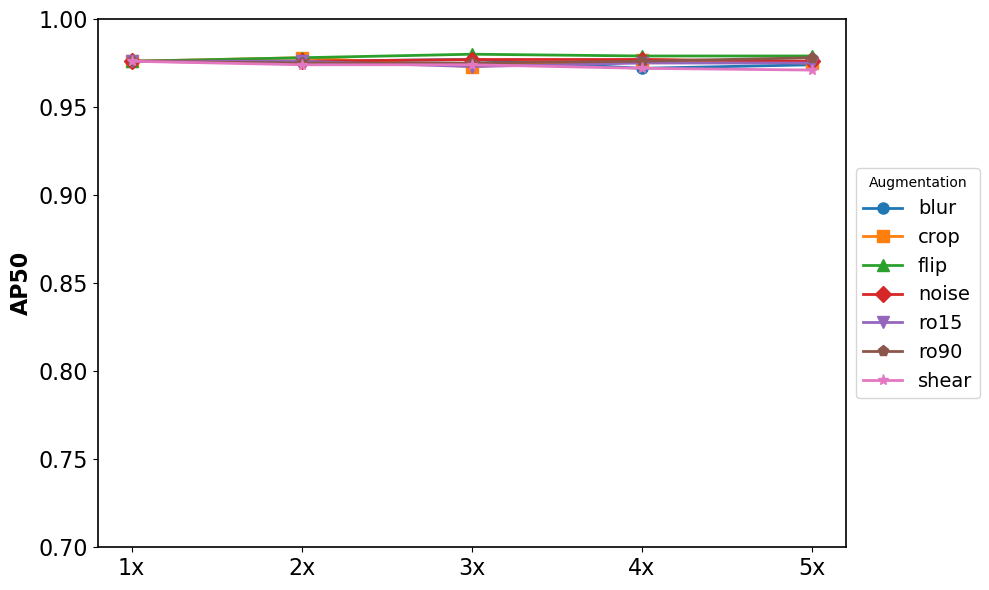

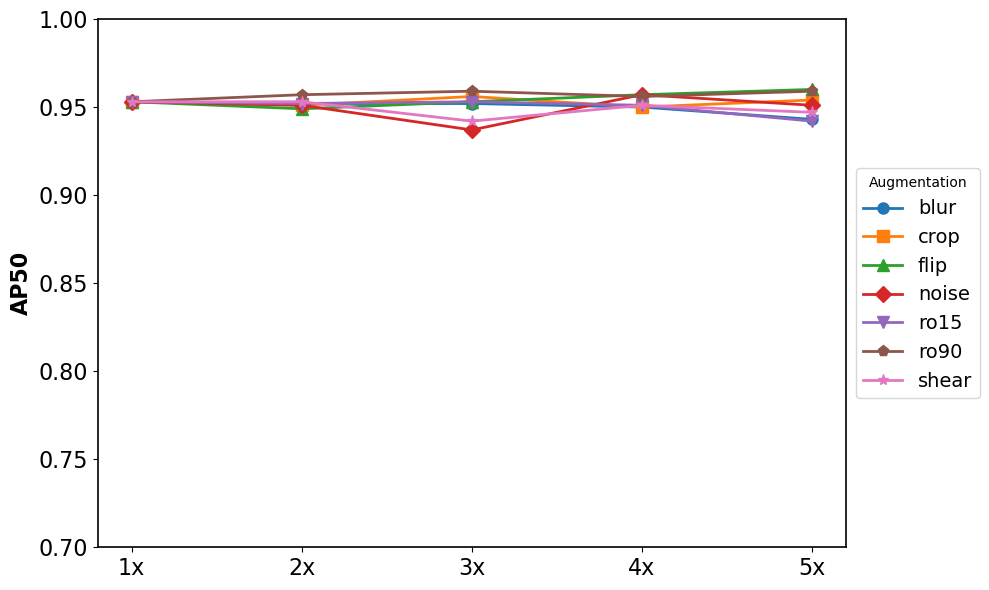

In [5]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt

# 1. CSV 파일들이 있는 폴더 경로 지정 (실제 폴더 경로로 수정해주세요!)
# 예: './augmentation_csv_results'
folder_path = 'C:/Users/ACE_LAB_AI/Desktop/object_detection_cell/full_data_1com_aug1to5' 

# 폴더 내의 모든 csv 파일 경로 가져오기
csv_files = glob.glob(os.path.join(folder_path, '*.csv'))

# 데이터를 하나로 모을 리스트
all_data = []

# 2. 모든 CSV 파일 읽어서 데이터 통합하기
for file in csv_files:
    # 파일명에서 증강 기법과 배수 추출 (예: 'blur_2_data.csv' -> 'blur', 2)
    filename = os.path.basename(file)
    parts = filename.split('_')
    
    aug_method = parts[0]       # 증강 기법 (blur, crop, flip 등)
    multiplier = int(parts[1])  # 배수 (2, 3, 4, 5)
    
    # CSV 읽기
    df = pd.read_csv(file)
    
    # 각 클래스의 mAP50 데이터 추출하여 리스트에 추가
    for index, row in df.iterrows():
        # 'all' 클래스는 제외하고 개별 클래스(E, L, M, N)만 타겟팅
        if row['Class'] in ['E', 'L', 'M', 'N']:
            all_data.append({
                'Class': row['Class'],
                'Augmentation': aug_method,
                'Multiplier': multiplier,
                'mAP50': row['mAP50']
            })

# 리스트를 하나의 데이터프레임으로 변환
merged_df = pd.DataFrame(all_data)

# 3. 클래스별로 4개의 그래프 그리기
target_classes = ['E', 'L', 'M', 'N']

# 한글 폰트 설정 및 그래프 스타일 (선택 사항)
plt.style.use('default') 

# 사용할 마커(심볼) 리스트 정의 (원, 네모, 위삼각형, 다이아몬드, 아래삼각형, 오각형, 별모양 등)
marker_list = ['o', 's', '^', 'D', 'v', 'p', '*']

for cls in target_classes:
    # 도화지 생성 및 배경 흰색 설정
    fig = plt.figure(figsize=(10, 6))
    fig.patch.set_facecolor('white')
    
    # 현재 그래프 영역(ax) 가져오기 및 배경 흰색 설정
    ax = plt.gca()
    ax.set_facecolor('white')
    
    # 사방에 검은색 테두리 그리기
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(1.2)
        spine.set_visible(True)
    
    # 현재 클래스 데이터만 필터링
    cls_data = merged_df[merged_df['Class'] == cls]
    
    # 증강 기법별로 라인 그래프 그리기 (총 7개 라인)
    aug_methods = cls_data['Augmentation'].unique()
    
    for i, aug in enumerate(aug_methods):
        # 특정 증강 기법 데이터만 뽑아서 배수(x축) 순서대로 정렬
        aug_data = cls_data[cls_data['Augmentation'] == aug].sort_values(by='Multiplier')
        
        # 기법 순서(i)에 따라 마커 리스트에서 다른 심볼을 가져와 적용
        current_marker = marker_list[i % len(marker_list)]
        
        # 마커 사이즈(markersize)를 조금 키워주면 논문용 그래프에서 식별이 더 잘 됩니다.
        plt.plot(aug_data['Multiplier'], aug_data['mAP50'], marker=current_marker, label=aug, linewidth=2, markersize=8)
    
    # 그래프 꾸미기
    #plt.title(f'mAP50 by Augmentation Methods - Class [{cls}]', fontsize=16, fontweight='bold')
    #plt.xlabel('Augmentation Multiplier (2x ~ 5x)', fontsize=12)
    plt.ylabel('AP50', fontsize=16, fontweight='bold')
    
    plt.ylim(0.7, 1.0)
    plt.yticks(fontsize=16) 

    # x축 눈금 확실하게 2, 3, 4, 5로 고정
    labels = ['1x', '2x', '3x', '4x','5x']
    plt.xticks([1, 2, 3, 4, 5], labels, fontsize=16) 
    
    # 범례 표시 (그래프 밖으로 빼려면 bbox_to_anchor 사용)
    plt.legend(title='Augmentation', loc='center left', bbox_to_anchor=(1, 0.5), fontsize=14)
    
    # 레이아웃 조정
    plt.tight_layout()
    
    # 1. 먼저 파일로 저장! (bbox_inches='tight'를 넣으면 범례가 잘리지 않아요)
    # 폴더가 없으면 에러가 날 수 있으니 저장 전에 os.makedirs 챙겨주시면 좋습니다.
    os.makedirs('paper_figure', exist_ok=True) 
    plt.savefig(f'paper_figure/figure2_{cls}.png', dpi=300, bbox_inches='tight')
    
    # 2. 그 다음에 화면에 출력!
    plt.show()

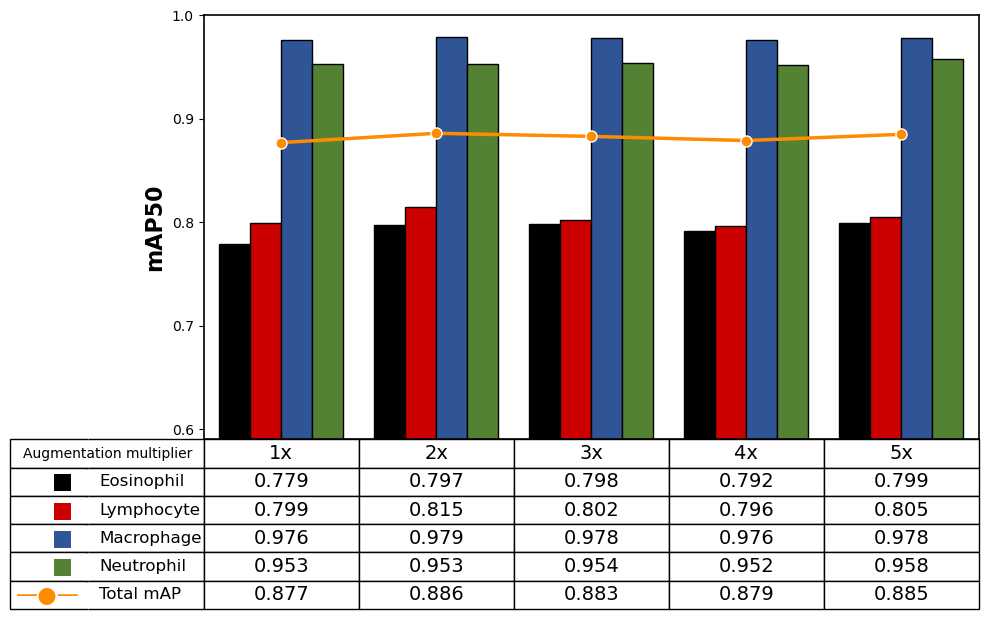

In [4]:
import os
import glob
import re
import pandas as pd
import numpy as np  
import matplotlib.pyplot as plt

# ==========================================
# 1. 데이터 불러오기 및 정렬
# ==========================================
folder_path = 'C:/Users/ACE_LAB_AI/Desktop/object_detection_cell/full_data_fullcom_aug1to5'
csv_files = glob.glob(os.path.join(folder_path, '*.csv'))

def extract_number(filepath):
    filename = os.path.basename(filepath)
    numbers = re.findall(r'\d+', filename) 
    return int(numbers[0]) if numbers else 0

csv_files = sorted(csv_files, key=extract_number)

mAP50_data = {'E': [], 'L': [], 'M': [], 'N': [], 'all': []}
columns = []

for file_path in csv_files:
    multiplier = extract_number(file_path)
    if multiplier == 1:
        columns.append('1x')
    else:
        columns.append(f'{multiplier}x')
        
    df = pd.read_csv(file_path)
    
    for cls in ['E', 'L', 'M', 'N', 'all']:
        val = df[df['Class'] == cls]['mAP50'].values[0]
        mAP50_data[cls].append(val)

# ==========================================
# 2. 그래프 그리기 (막대 + 꺾은선 혼합)
# ==========================================
plt.style.use('default') 
fig, ax = plt.subplots(figsize=(10, 8)) 

fig.patch.set_facecolor('white')
ax.set_facecolor('white')

x = np.arange(len(columns))
width = 0.2  

# [수정됨] 막대 그래프 색상을 이전에 사용했던 컬러로 복구!
color_E = 'black'
color_L = '#CC0000'  # 빨간색
color_M = '#2F5597'  # 파란색
color_N = '#548235'  # 초록색
color_Total = '#FF8C00' # Total mAP는 다른 색과 겹치지 않게 진한 주황색으로 강조

# 막대 그래프 그리기
ax.bar(x - 1.5*width, mAP50_data['E'], width, color=color_E, edgecolor='black')
ax.bar(x - 0.5*width, mAP50_data['L'], width, color=color_L, edgecolor='black')
ax.bar(x + 0.5*width, mAP50_data['M'], width, color=color_M, edgecolor='black')
ax.bar(x + 1.5*width, mAP50_data['N'], width, color=color_N, edgecolor='black')

# Total mAP 꺾은선 그래프 겹쳐 그리기
ax.plot(x, mAP50_data['all'], color=color_Total, marker='o', markerfacecolor=color_Total, markeredgecolor='white', markersize=8, linewidth=2.5)

# Y축 설정
ax.set_ylabel('mAP50', fontsize=16, fontweight='bold')
ax.set_ylim(0.59, 1.0)
ax.set_yticks([0.6, 0.7, 0.8, 0.9, 1.0])

ax.set_xticks([]) 
ax.tick_params(axis='x', which='both', bottom=False, top=False)

for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1.2)
    spine.set_visible(True)

# ==========================================
# 3. 마법의 꼼수 표(Table) 만들기
# ==========================================
ax.set_xlim(-0.5, len(columns) - 0.5)

table_columns = ['', 'Augmentation multiplier'] + columns

def format_data(data_list):
    return [f"{v:.3f}" for v in data_list]

cell_text = [
    ['■ ', 'Eosinophil'] + format_data(mAP50_data['E']),
    ['■ ', 'Lymphocyte'] + format_data(mAP50_data['L']),
    ['■ ', 'Macrophage'] + format_data(mAP50_data['M']),
    ['■ ', 'Neutrophil'] + format_data(mAP50_data['N']),
    ['—●—', 'Total mAP'] + format_data(mAP50_data['all'])
]

widths = [0.08, 0.12] + [0.16] * len(columns)

table = ax.table(cellText=cell_text, 
                 colLabels=table_columns, 
                 loc='bottom', 
                 cellLoc='center', 
                 colWidths=widths,
                 bbox=[-0.25, -0.4, 1.25, 0.4]) 

table.auto_set_font_size(False)
table.set_fontsize(14)

colors = [color_E, color_L, color_M, color_N, color_Total]

for (row, col), cell in table.get_celld().items():
    if row == 0: 
        cell.set_text_props(fontweight='normal')
        if col == 0: 
            cell.visible_edges = 'LBT' 
        elif col == 1: 
            cell.visible_edges = 'RBT'
            # 1. 딱 이 칸(Augmentation multiplier)만 크기 10으로 고정
            # 2. 잘리지 않게 가운데 정렬(center) 또는 오른쪽 정렬(right)
            cell.set_text_props(fontsize=10, ha='right') 
        else:
            # 3. 1x, 2x 등 나머지 첫 행 글자들은 원래 크기(14) 유지
            cell.set_text_props(fontsize=14) 
            
    elif row > 0: 
        if col == 0:
            cell.set_text_props(color=colors[row-1], fontweight='normal', fontsize=16)
            cell.get_text().set_ha('right')
            cell.visible_edges = 'LBT'
        elif col == 1:
            cell.set_text_props(fontweight='normal', fontsize=12)
            cell.get_text().set_ha('left')
            cell.visible_edges = 'RBT'

plt.subplots_adjust(bottom=0.35) 
plt.savefig('figure1_bar_and_line_color.png', dpi=300, bbox_inches='tight')
plt.show()

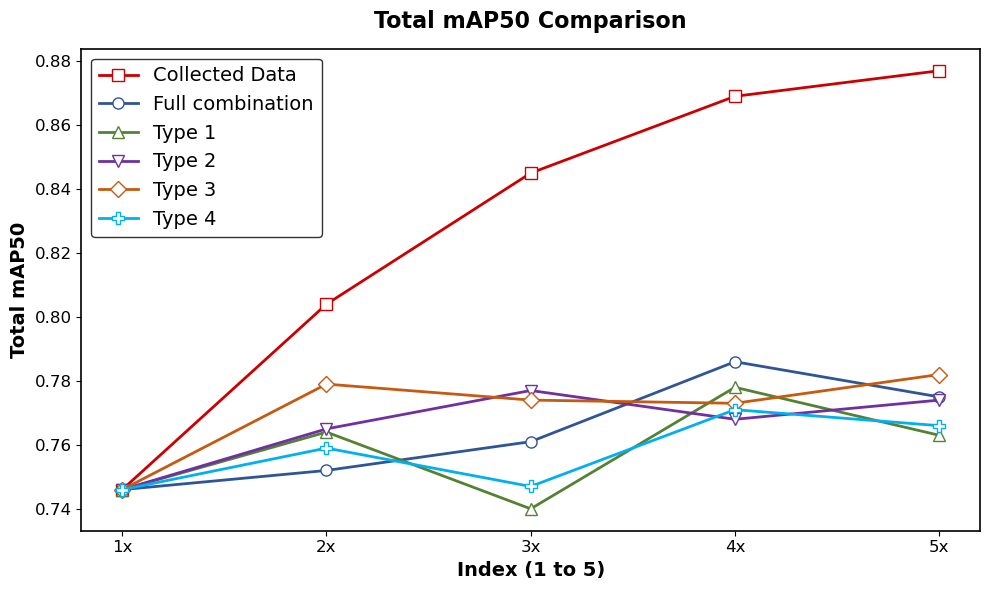

In [5]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. 파일 경로 및 데이터 추출
# ==========================================
# 폴더 경로 설정 (실제 경로에 맞게 필요시 수정하세요)
folder_path = 'C:/Users/ACE_LAB_AI/Desktop/object_detection_cell/onefifth_data_best4_full_com_aug1to5'

# 각 그룹 데이터를 담을 리스트
group1_x, group1_y = [], []  # Full combination (full_aug1 ~ full_aug5)
group2_x, group2_y = [], []  # Collected Data (cp1 ~ cp5)
group3_x, group3_y = [], []  # Type 1 (1st_aug1 ~ 1st_aug5)
group4_x, group4_y = [], []  # Type 2 (2nd_aug1 ~ 2nd_aug5)
group5_x, group5_y = [], []  # Type 3 (3rd_aug1 ~ 3rd_aug5)
group6_x, group6_y = [], []  # Type 4 (4th_aug1 ~ 4th_aug5)

# 데이터를 불러오는 공통 함수
def load_data(file_pattern, x_list, y_list):
    for i in range(1, 6):
        # 주어진 패턴에 1~5 숫자를 넣어 파일명 완성
        file_name = file_pattern.format(i)
        file_path = os.path.join(folder_path, file_name)
        
        if os.path.exists(file_path):
            df = pd.read_csv(file_path)
            # 'Class'가 'all'인 행의 'mAP50' 값 추출
            val = df[df['Class'] == 'all']['mAP50'].values[0]
            x_list.append(i)  # X축 위치는 1, 2, 3, 4, 5로 고정
            y_list.append(val)

# 변경된 파일명에 맞춰 각각의 데이터 로드
load_data('full_aug{}_data.csv', group1_x, group1_y)
load_data('cp{}_data.csv', group2_x, group2_y)
load_data('1st_aug{}_data.csv', group3_x, group3_y)
load_data('2nd_aug{}_data.csv', group4_x, group4_y)
load_data('3rd_aug{}_data.csv', group5_x, group5_y)
load_data('4th_aug{}_data.csv', group6_x, group6_y)

# ==========================================
# 2. 그래프 그리기 (미니멀 화이트 & 블랙 테두리)
# ==========================================
plt.style.use('default') 
fig, ax = plt.subplots(figsize=(10, 6))

# 배경 흰색 고정
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

# 기존 두 그룹의 선 그래프 
ax.plot(group2_x, group2_y, color='#CC0000', marker='s', markerfacecolor='white', markeredgecolor='#CC0000', markersize=8, linewidth=2, label='Collected Data')
ax.plot(group1_x, group1_y, color='#2F5597', marker='o', markerfacecolor='white', markeredgecolor='#2F5597', markersize=8, linewidth=2, label='Full combination')

# 새로운 4개 그룹 선 그래프 (각각 다른 색상과 마커 적용)
ax.plot(group3_x, group3_y, color='#548235', marker='^', markerfacecolor='white', markeredgecolor='#548235', markersize=8, linewidth=2, label='Type 1')
ax.plot(group4_x, group4_y, color='#7030A0', marker='v', markerfacecolor='white', markeredgecolor='#7030A0', markersize=8, linewidth=2, label='Type 2')
ax.plot(group5_x, group5_y, color='#C55A11', marker='D', markerfacecolor='white', markeredgecolor='#C55A11', markersize=8, linewidth=2, label='Type 3')
ax.plot(group6_x, group6_y, color='#00B0F0', marker='P', markerfacecolor='white', markeredgecolor='#00B0F0', markersize=8, linewidth=2, label='Type 4')

# 축 및 라벨 설정
ax.set_title('Total mAP50 Comparison', fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Index (1 to 5)', fontsize=14, fontweight='bold')
ax.set_ylabel('Total mAP50', fontsize=14, fontweight='bold')

# X축을 1~5 정수로 설정
plt.xticks(ticks=[1, 2, 3, 4, 5], labels=['1x', '2x', '3x', '4x', '5x'])

# 사방에 검은색 테두리 씌우기
for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1.2)
    spine.set_visible(True)

plt.tick_params(axis='both', which='major', labelsize=12)

# 범례 추가 (데이터가 많아졌으므로 크기와 위치를 적절히 조절)
ax.legend(loc='best', frameon=True, edgecolor='black', fontsize=14)

# 레이아웃 조정 및 저장
plt.tight_layout()
plt.savefig('figure8_total_map_comparison_updated.png', dpi=300, bbox_inches='tight')
plt.show()

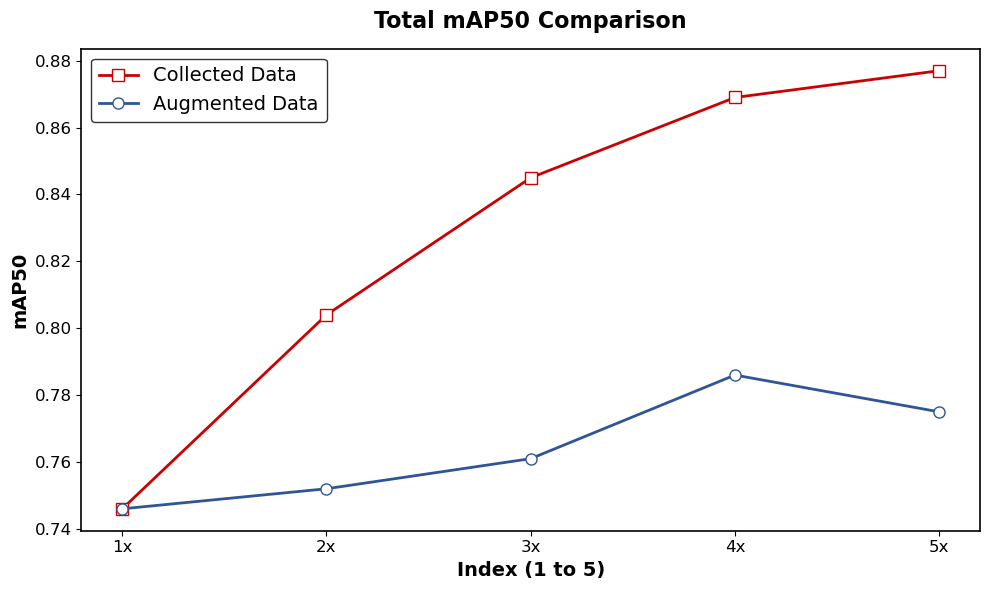

In [14]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. 파일 경로 및 데이터 추출
# ==========================================
# 폴더 경로 설정 (실제 경로에 맞게 필요시 수정하세요)
folder_path = 'C:/Users/ACE_LAB_AI/Desktop/object_detection_cell/onefifth_data_best4_full_com_aug1to5'

# 각 그룹 데이터를 담을 리스트
group1_x, group1_y = [], []  # Augmented data (full_aug1 ~ full_aug5)
group2_x, group2_y = [], []  # Collected Data (cp1 ~ cp5)

# 데이터를 불러오는 공통 함수
def load_data(file_pattern, x_list, y_list):
    for i in range(1, 6):
        # 주어진 패턴에 1~5 숫자를 넣어 파일명 완성
        file_name = file_pattern.format(i)
        file_path = os.path.join(folder_path, file_name)
        
        if os.path.exists(file_path):
            df = pd.read_csv(file_path)
            # 'Class'가 'all'인 행의 'mAP50' 값 추출
            val = df[df['Class'] == 'all']['mAP50'].values[0]
            x_list.append(i)  # X축 위치는 1, 2, 3, 4, 5로 고정
            y_list.append(val)

# 변경된 파일명에 맞춰 각각의 데이터 로드
load_data('full_aug{}_data.csv', group1_x, group1_y)
load_data('cp{}_data.csv', group2_x, group2_y)

# ==========================================
# 2. 그래프 그리기 (미니멀 화이트 & 블랙 테두리)
# ==========================================
plt.style.use('default') 
fig, ax = plt.subplots(figsize=(10, 6))

# 배경 흰색 고정
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

# 기존 두 그룹의 선 그래프 
ax.plot(group2_x, group2_y, color='#CC0000', marker='s', markerfacecolor='white', markeredgecolor='#CC0000', markersize=8, linewidth=2, label='Collected Data')

# 'Full combination' 대신 'Augmented Data'로 라벨 변경
ax.plot(group1_x, group1_y, color='#2F5597', marker='o', markerfacecolor='white', markeredgecolor='#2F5597', markersize=8, linewidth=2, label='Augmented Data')

# 축 및 라벨 설정
ax.set_title('Total mAP50 Comparison', fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Index (1 to 5)', fontsize=14, fontweight='bold')
ax.set_ylabel('mAP50', fontsize=14, fontweight='bold')

# X축을 1~5 정수로 설정
plt.xticks(ticks=[1, 2, 3, 4, 5], labels=['1x', '2x', '3x', '4x', '5x'])

# 사방에 검은색 테두리 씌우기
for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1.2)
    spine.set_visible(True)

plt.tick_params(axis='both', which='major', labelsize=12)

# 범례 추가
ax.legend(loc='best', frameon=True, edgecolor='black', fontsize=14)

# 레이아웃 조정 및 저장
plt.tight_layout()
plt.savefig('figure8_total_map_comparison_updated.png', dpi=300, bbox_inches='tight')
plt.show()

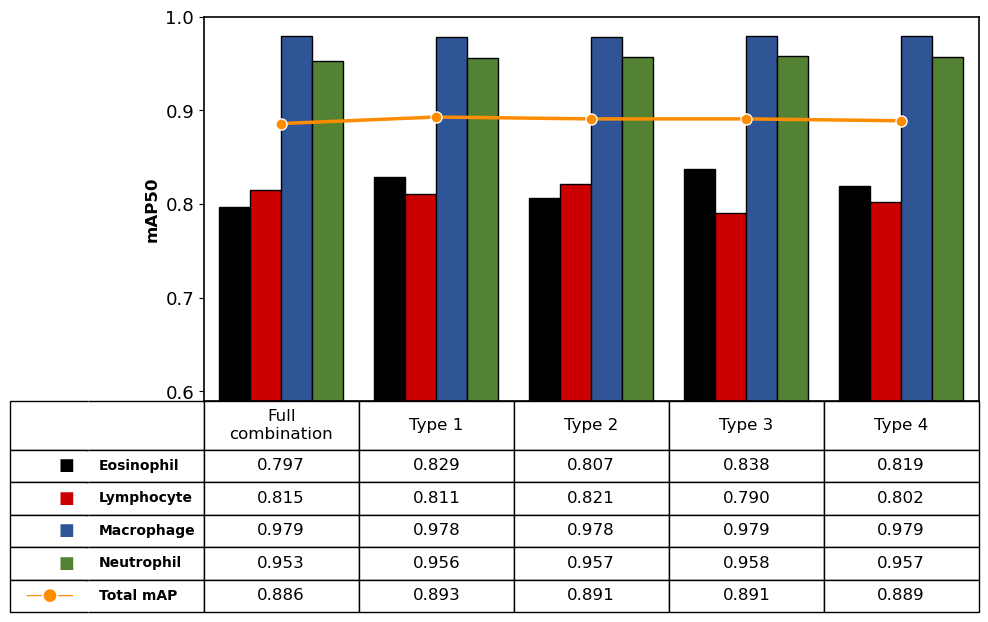

In [6]:
import os
import pandas as pd
import numpy as np  
import matplotlib.pyplot as plt

# ==========================================
# 1. 데이터 갈아끼우기 (지정된 파일명으로 직접 로드)
# ==========================================
base_path = 'C:/Users/ACE_LAB_AI/Desktop/object_detection_cell'

# 두 개의 개별 경로 설정 (실제 경로명에 맞춰 수정해 주세요)
folder_path_1 = os.path.join(base_path, 'full_data_best4_aug1to5')  # Type 1~4 데이터 경로
folder_path_2 = os.path.join(base_path, 'full_data_fullcom_aug1to5')                       # Full combination 데이터 경로

# 텍스트 길이에 맞게 줄바꿈 적용
custom_labels = [
    "Full\ncombination",
    "Type 1",
    "Type 2",
    "Type 3",
    "Type 4"
]

# 명시한 파일 이름과 라벨 매핑 (순서: Full -> Type1 -> Type2 -> Type3 -> Type4)
files_to_plot = [
    (os.path.join(folder_path_2, 'full_2_data.csv'), custom_labels[0]),
    (os.path.join(folder_path_1, '1st_aug2_data.csv'), custom_labels[1]),
    (os.path.join(folder_path_1, '2nd_aug2_data.csv'), custom_labels[2]),
    (os.path.join(folder_path_1, '3rd_aug2_data.csv'), custom_labels[3]),
    (os.path.join(folder_path_1, '4th_aug2_data.csv'), custom_labels[4])
]

mAP50_data = {'E': [], 'L': [], 'M': [], 'N': [], 'all': []}
columns = [label for _, label in files_to_plot]

for filepath, _ in files_to_plot:
    df = pd.read_csv(filepath)
    # 컬럼명이 class인지 Class인지 유연하게 대처
    class_col = 'Class' if 'Class' in df.columns else 'class'
    map_col = 'mAP50' if 'mAP50' in df.columns else 'mAP@0.5'
    
    for cls in ['E', 'L', 'M', 'N', 'all']:
        val = df[df[class_col] == cls][map_col].values[0]
        mAP50_data[cls].append(val)

# ==========================================
# 2. 그래프 그리기 (원본 코드 그대로!)
# ==========================================
plt.style.use('default') 
fig, ax = plt.subplots(figsize=(10, 8)) 

fig.patch.set_facecolor('white')
ax.set_facecolor('white')

x = np.arange(len(columns))
width = 0.2  

color_E = 'black'
color_L = '#CC0000'  
color_M = '#2F5597'  
color_N = '#548235'  
color_Total = '#FF8C00' 

ax.bar(x - 1.5*width, mAP50_data['E'], width, color=color_E, edgecolor='black')
ax.bar(x - 0.5*width, mAP50_data['L'], width, color=color_L, edgecolor='black')
ax.bar(x + 0.5*width, mAP50_data['M'], width, color=color_M, edgecolor='black')
ax.bar(x + 1.5*width, mAP50_data['N'], width, color=color_N, edgecolor='black')

ax.plot(x, mAP50_data['all'], color=color_Total, marker='o', markerfacecolor=color_Total, markeredgecolor='white', markersize=8, linewidth=2.5)

ax.set_ylabel('mAP50', fontsize=12, fontweight='bold')
ax.set_ylim(0.59, 1.0)
ax.set_yticks([0.6, 0.7, 0.8, 0.9, 1.0])
ax.tick_params(axis='y', labelsize=13)

ax.set_xticks([]) 
ax.tick_params(axis='x', which='both', bottom=False, top=False)

for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1.2)
    spine.set_visible(True)

# ==========================================
# 3. 마법의 꼼수 표(Table) 만들기 (글자 크기 키움!)
# ==========================================
ax.set_xlim(-0.5, len(columns) - 0.5)

table_columns = ['', ''] + columns

def format_data(data_list):
    return [f"{v:.3f}" for v in data_list]

cell_text = [
    ['■ ', 'Eosinophil'] + format_data(mAP50_data['E']),
    ['■ ', 'Lymphocyte'] + format_data(mAP50_data['L']),
    ['■ ', 'Macrophage'] + format_data(mAP50_data['M']),
    ['■ ', 'Neutrophil'] + format_data(mAP50_data['N']),
    ['—●— ', 'Total mAP'] + format_data(mAP50_data['all'])
]

widths = [0.08, 0.12] + [0.16] * len(columns)

table = ax.table(cellText=cell_text, 
                 colLabels=table_columns, 
                 loc='bottom', 
                 cellLoc='center', 
                 colWidths=widths,
                 bbox=[-0.25, -0.55, 1.25, 0.55]) 

table.auto_set_font_size(False)
# 💡 1. 표 안의 데이터(숫자)와 맨 윗줄(Type1, Type2 등) 글자 크기 (기존 9 -> 12로 변경)
table.set_fontsize(12) 

colors = [color_E, color_L, color_M, color_N, color_Total]

for (row, col), cell in table.get_celld().items():
    if row == 0: 
        cell.set_text_props(fontweight='normal')
        if col == 0: cell.visible_edges = 'LBT' 
        if col == 1: cell.visible_edges = 'RBT' 
    elif row > 0: 
        if col == 0:
            # 💡 2. 맨 왼쪽 네모 기호(■) 크기 (기존 12 -> 14로 변경)
            cell.set_text_props(color=colors[row-1], fontweight='normal', fontsize=12)
            cell.get_text().set_ha('right')
            cell.visible_edges = 'LBT'
        elif col == 1:
            # 💡 3. 표 왼쪽 이름(Eosinophil 등) 글자 크기 (기존 지정 없음 -> 12로 추가)
            cell.set_text_props(fontweight='bold', fontsize=10)
            cell.get_text().set_ha('left')
            cell.visible_edges = 'RBT'

# ==========================================
# ★ [추가된 꼼수] 첫 번째 행(라벨)만 세로로 길게 늘리기 ★
# ==========================================
cell_dict = table.get_celld()
top_y = 0.0 

for row in range(6): 
    for col in range(len(columns) + 2):
        if (row, col) in cell_dict:
            cell = cell_dict[(row, col)]
            
            x = cell.get_x()
            w = cell.get_width()
            
            if row == 0:
                h = 0.15 
                y = top_y - h
            else:
                # 💡 만약 글자를 더 크게 키웠는데 위아래가 겹치면 이 높이(h=0.10)를 조금 더 키우세요 (예: 0.12)
                h = 0.10 
                y = top_y - 0.20 - (row * 0.05) 
                
            cell.set_bounds(x, y, w, h)

plt.subplots_adjust(bottom=0.4) 
plt.savefig('figure3_swapped_data.png', dpi=300, bbox_inches='tight')
plt.show()

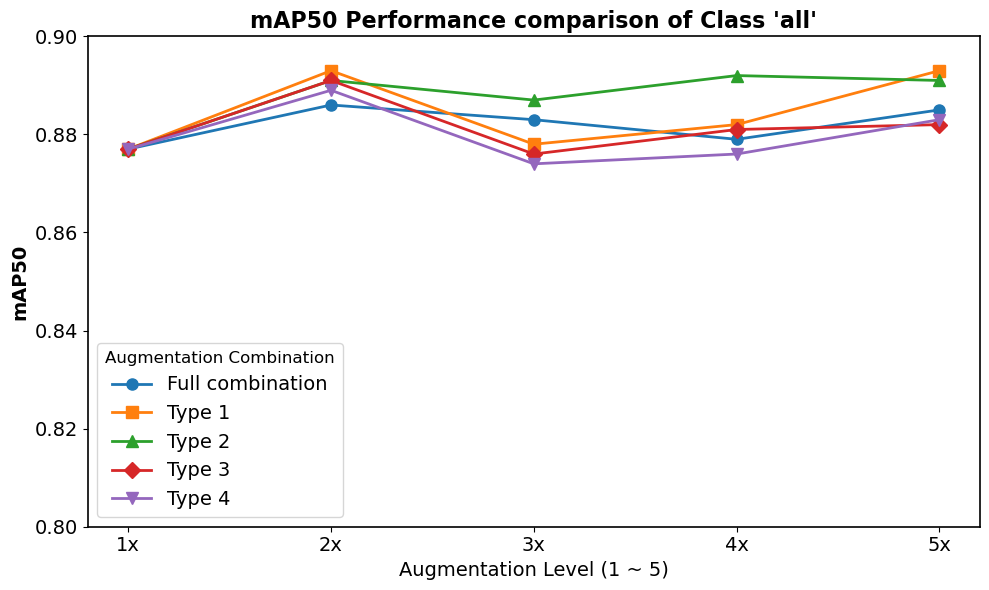

In [6]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt

# 1. 상위 폴더 경로 지정 (실제 경로에 맞게 수정해주세요)
base_folder = 'C:/Users/ACE_LAB_AI/Desktop/object_detection_cell'

# 두 개의 폴더 경로 설정
folder_full = os.path.join(base_folder, 'full_data_fullcom_aug1to5')
folder_aug = os.path.join(base_folder, 'full_data_best4_aug1to5')

all_data = []

# 2-1. 'full' 데이터 읽기 (csv_for_figure1 폴더)
full_csv_files = glob.glob(os.path.join(folder_full, 'full_*_data.csv'))

for file in full_csv_files:
    filename = os.path.basename(file)
    # 파일명에서 배수 추출 ('full_1_data.csv' -> 1)
    multiplier = int(filename.split('_')[1])
    
    df = pd.read_csv(file)
    
    # Class가 'all'인 행의 mAP50 값 추출
    map50_value = df[df['Class'] == 'all']['mAP50'].values[0]
    all_data.append({'Group': 'full', 'Multiplier': multiplier, 'mAP50': map50_value})

# 2-2. '1st' ~ '4th' 데이터 읽기 (csv_for_figure4 폴더)
aug_csv_files = glob.glob(os.path.join(folder_aug, '*_aug*.csv'))

for file in aug_csv_files:
    filename = os.path.basename(file)
    
    # 그룹 추출 ('1st', '2nd', '3rd', '4th')
    group = filename.split('_')[0] 
    
    # 배수 추출 ('aug1.csv' -> 1)
    multiplier_str = filename.split('_')[1].replace('aug', '').replace('.csv', '')
    multiplier = int(multiplier_str)
    
    df = pd.read_csv(file)
    
    # Class가 'all'인 행의 mAP50 값 추출
    map50_value = df[df['Class'] == 'all']['mAP50'].values[0]
    all_data.append({'Group': group, 'Multiplier': multiplier, 'mAP50': map50_value})

# 모든 데이터를 데이터프레임으로 변환
df_all = pd.DataFrame(all_data)

# 3. 그래프 그리기 준비
# 그릴 순서 정의
groups = ['full', '1st', '2nd', '3rd', '4th']

# 요청하신 커스텀 범례 맵핑 딕셔너리
custom_labels = {
    'full': "Full combination",
    '1st': "Type 1",
    '2nd': "Type 2",
    '3rd': "Type 3",
    '4th': "Type 4"
}

# 4. 그래프 도화지 설정
plt.figure(figsize=(10, 6))
ax = plt.gca()
ax.set_facecolor('white')

# 테두리 설정
for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1.2)
    spine.set_visible(True)

# 5. 각 그룹별로 라인 그래프 그리기
# 그룹별로 사용할 마커 종류 지정 (o: 원, s: 사각형, ^: 위를 향한 삼각형, D: 다이아몬드, v: 아래를 향한 삼각형)
custom_markers = {
    'full': 'o', 
    '1st': 's',  
    '2nd': '^',  
    '3rd': 'D',  
    '4th': 'v'   
}

for group in groups:
    # 특정 그룹 데이터만 뽑아서 배수(x축) 순서대로 정렬
    group_data = df_all[df_all['Group'] == group].sort_values(by='Multiplier')
    
    # 그래프 그리기 (marker='o' 부분을 custom_markers[group]으로 변경)
    plt.plot(group_data['Multiplier'], group_data['mAP50'], marker=custom_markers[group], 
             label=custom_labels[group], linewidth=2, markersize=8)

# 6. 그래프 꾸미기
plt.title("mAP50 Performance comparison of Class 'all'", fontsize=16, fontweight='bold')
plt.xlabel('Augmentation Level (1 ~ 5)', fontsize=14)
plt.ylabel('mAP50', fontsize=14, fontweight='bold')

# x축 눈금 1, 2, 3, 4, 5 고정
labels = ['1x', '2x', '3x', '4x','5x']
plt.xticks([1, 2, 3, 4, 5], labels, fontsize=14) 

# y축 0.6 ~ 1.0 고정
plt.ylim(0.8, 0.9) 

plt.tick_params(axis='both', which='major', labelsize=14)

# 범례 표시 (텍스트가 길기 때문에 그래프 바깥 우측에 배치)
plt.legend(title='Augmentation Combination', loc='lower left', fontsize=14, title_fontsize=12)

plt.tight_layout()

# 파일로 저장 (범례가 잘리지 않도록 bbox_inches='tight' 필수)
plt.savefig('paper_figure/figure5a.png', dpi=300, bbox_inches='tight')

# 화면 출력
plt.show()

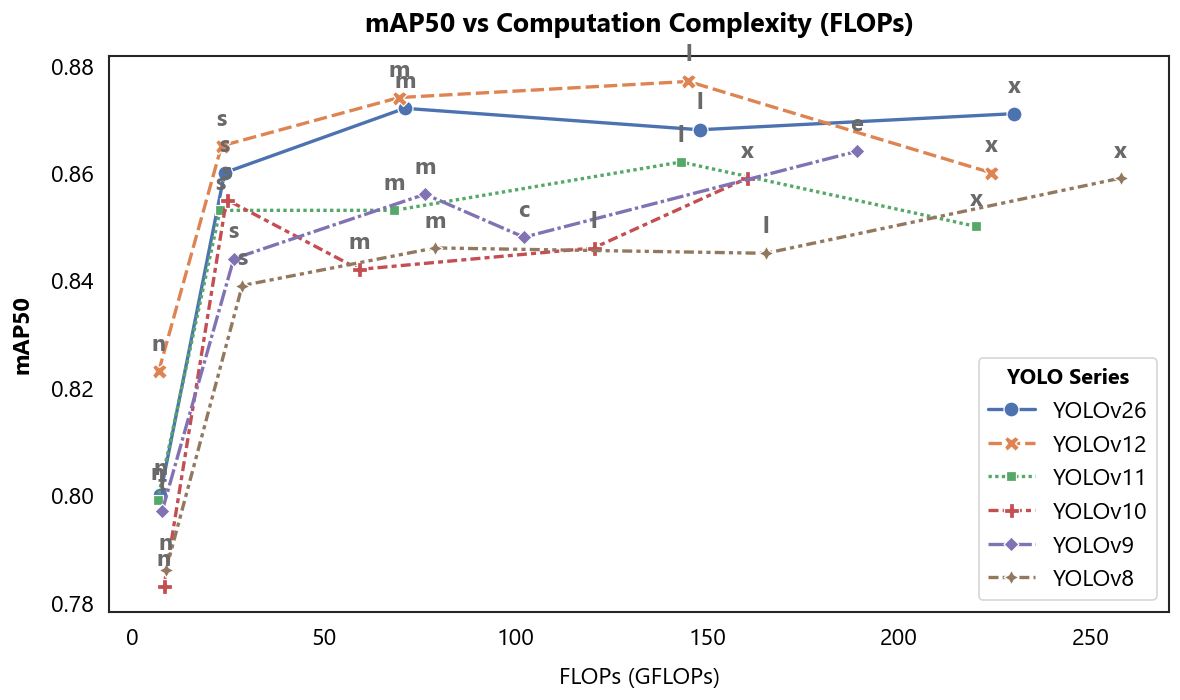

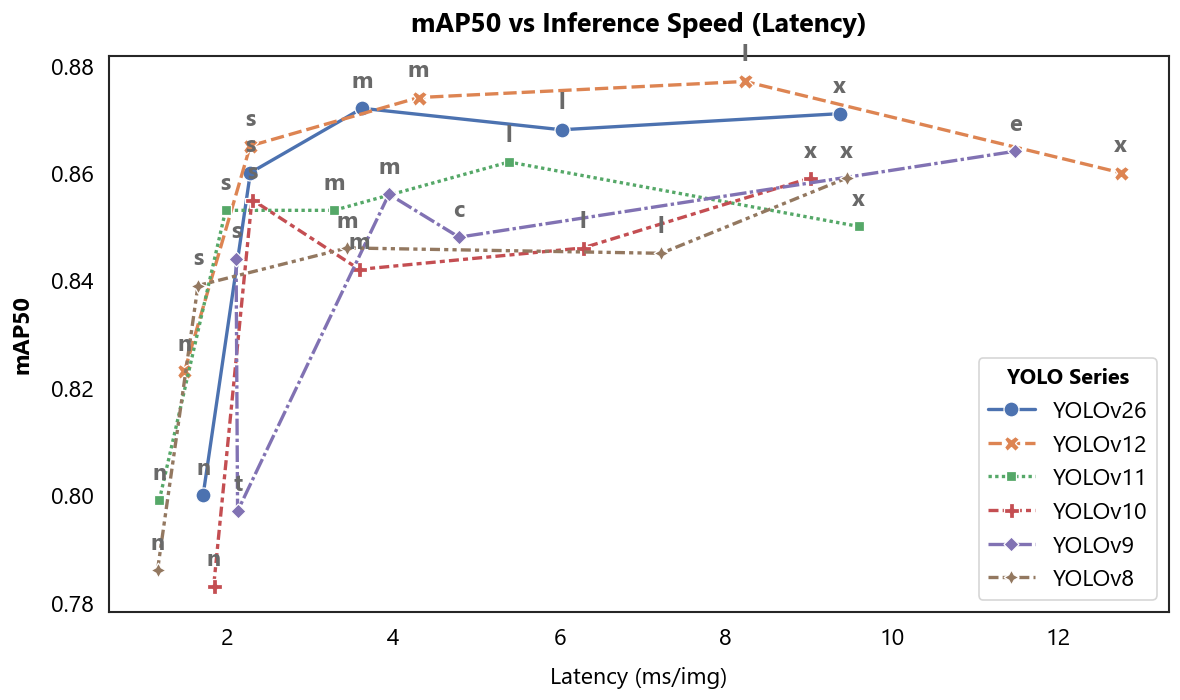

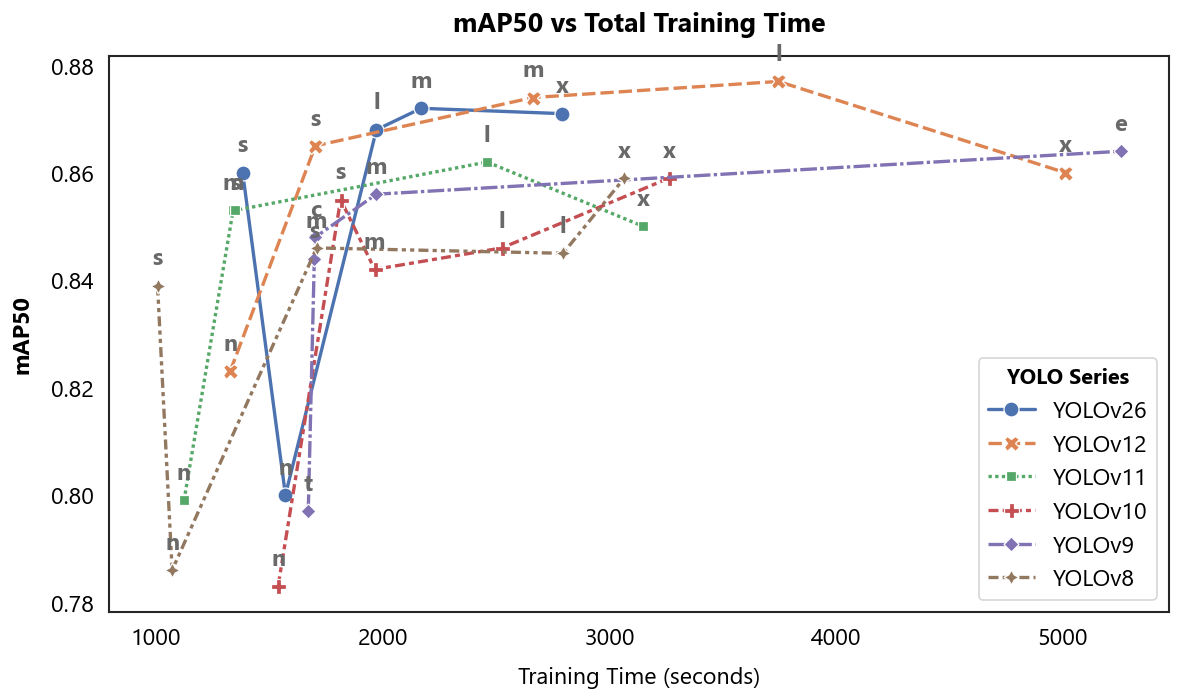

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. 파일 경로 및 FLOPs 데이터 정의
summary_csv_path = r"C:/Users/ACE_LAB_AI/Desktop/object_detection_cell/model_comparison_results/AI-Cell-Image-154_ALL_MODELS_SUMMARY.csv"

# 공식 논문/저장소 기준 정확한 FLOPs (입력 크기 640x640, 단위: GFLOPs) 반영
flops_dict = {
    "yolov8n.pt": 8.7,   "yolov8s.pt": 28.6,  "yolov8m.pt": 78.9,  "yolov8l.pt": 165.2, "yolov8x.pt": 257.8,
    "yolov9t.pt": 7.7,   "yolov9s.pt": 26.4,  "yolov9m.pt": 76.3,  "yolov9c.pt": 102.1, "yolov9e.pt": 189.0,
    "yolov10n.pt": 8.2,  "yolov10s.pt": 24.5, "yolov10m.pt": 59.1, "yolov10l.pt": 120.3, "yolov10x.pt": 160.4,
    "yolo11n.pt": 6.5,   "yolo11s.pt": 22.8,  "yolo11m.pt": 68.3,  "yolo11l.pt": 143.1, "yolo11x.pt": 220.1,
    "yolo12n.pt": 6.8,   "yolo12s.pt": 23.2,  "yolo12m.pt": 69.5,  "yolo12l.pt": 145.0, "yolo12x.pt": 224.0,
    "yolo26n.pt": 7.2,   "yolo26s.pt": 24.0,  "yolo26m.pt": 71.0,  "yolo26l.pt": 148.0, "yolo26x.pt": 230.0,
}

# 2. 데이터 로드 및 전처리
df = pd.read_csv(summary_csv_path)

# FLOPs 컬럼 추가
df['FLOPs(G)'] = df['Model'].map(flops_dict)

# 모델명 분리 및 대문자화 (yolo -> YOLOv)
def parse_model_info(model_name):
    name = model_name.replace('.pt', '')
    size = name[-1]       # 맨 마지막 글자 (n, s, m, l, x, t, c, e)
    series = name[:-1]    # 크기를 제외한 앞부분
    
    if series.startswith('yolo') and not series.startswith('yolov'):
        series = series.replace('yolo', 'YOLOv')
    elif series.startswith('yolov'):
        series = series.replace('yolov', 'YOLOv')
        
    return pd.Series([series, size])

df[['Series', 'Size']] = df['Model'].apply(parse_model_info)

# 사이즈 정렬 순서 정의
size_order = ['n', 't', 's', 'm', 'c', 'l', 'x', 'e']
df['Size'] = pd.Categorical(df['Size'], categories=size_order, ordered=True)
df = df.sort_values(by=['Series', 'Size'])

# 3. 데이터 시각화 설정
sns.set_theme(style="white")
plt.rcParams['font.family'] = 'Segoe UI'
plt.rcParams['axes.unicode_minus'] = False

# ★ 전반적인 폰트 크기 및 색상을 완전한 검정색으로 고정 설정
plt.rcParams.update({
    'font.size': 12,
    'text.color': 'black',
    'axes.labelcolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black'
})

# X축 지표와 타이틀 설정
x_metrics = {
    'FLOPs(G)': ('FLOPs (GFLOPs)', 'mAP50 vs Computation Complexity (FLOPs)'),
    'Inference_Time(ms/img)': ('Latency (ms/img)', 'mAP50 vs Inference Speed (Latency)'),
    'Train_Time(sec)': ('Training Time (seconds)', 'mAP50 vs Total Training Time')
}

# 범례 순서 (대문자에 맞춰서)
legend_order = ['YOLOv26', 'YOLOv12', 'YOLOv11', 'YOLOv10', 'YOLOv9', 'YOLOv8']

# 3개의 그래프를 순서대로 그리기
for x_col, (x_label, title) in x_metrics.items():
    plt.figure(figsize=(10, 6), dpi=120)
    
    sns.lineplot(
        data=df, 
        x=x_col, 
        y='mAP50', 
        hue='Series', 
        style='Series',
        hue_order=legend_order,
        style_order=legend_order,
        markers=True, 
        markersize=9, 
        linewidth=2,
    )
    
    # 점 옆에 n, s, m, l, x, t, c, e 텍스트 라벨 추가 (검정색, 투명도 제거)
    for i, row in df.dropna(subset=[x_col, 'mAP50']).iterrows():
        plt.text(
            row[x_col], 
            row['mAP50'] + 0.003,
            row['Size'], 
            fontsize=14, 
            ha='center', 
            va='bottom',
            weight='bold',
            color='dimgray',
            alpha=1.0
        )
        
    # 축 및 타이틀 색상 명시적 검정색 설정
    plt.title(title, fontsize=16, pad=15, weight='bold', color='black')
    plt.xlabel(x_label, fontsize=14, labelpad=10, color='black')
    plt.ylabel('mAP50', fontsize=14, labelpad=10, color='black', fontweight='bold')
    plt.xticks(fontsize=14) 
    plt.yticks(fontsize=14) 
    
    # 축의 눈금(숫자)도 검정색으로 확실하게 지정
    plt.tick_params(colors='black')
    
    # 범례 설정
    legend = plt.legend(
        title="YOLO Series", 
        loc='lower right', 
        frameon=True, 
        fontsize=14,
        title_fontsize=13
    )
    
    # 범례 제목과 항목 글씨를 완전한 검은색으로 변경
    plt.setp(legend.get_title(), color='black', weight='bold')
    for text in legend.get_texts():
        text.set_color('black')

    plt.tight_layout()
    
    save_filename = f"plot_mAP50_vs_{x_col.split('(')[0]}.png"
    plt.savefig(save_filename, dpi=300, bbox_inches='tight')
    plt.show()

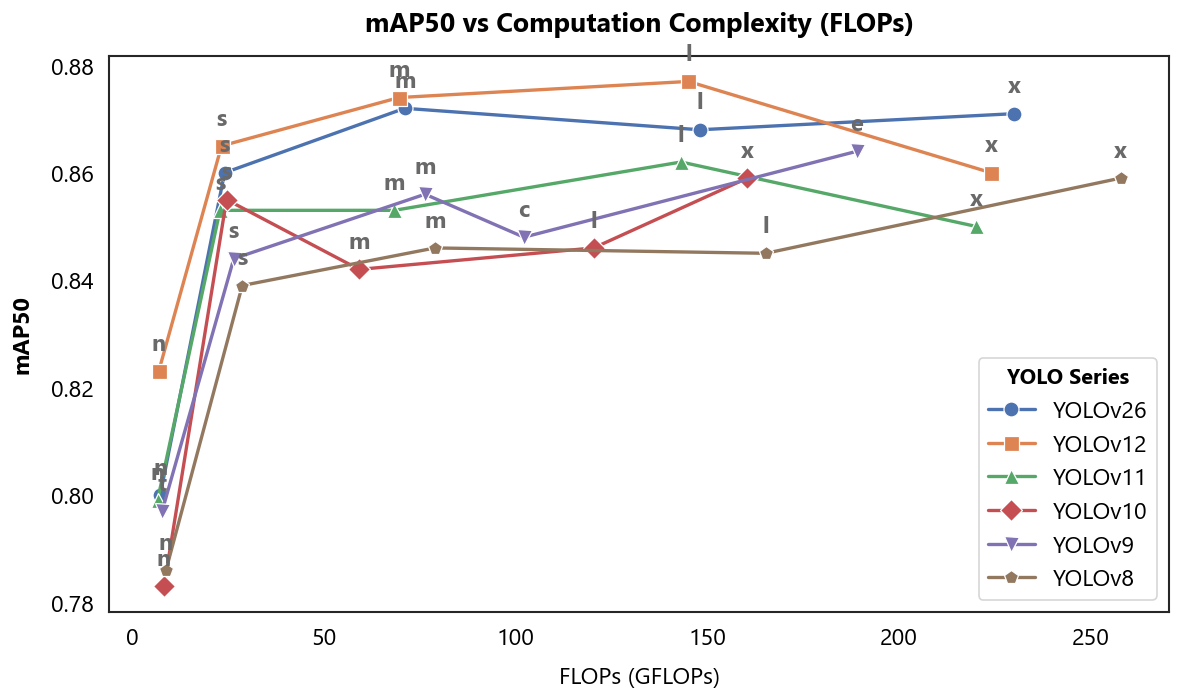

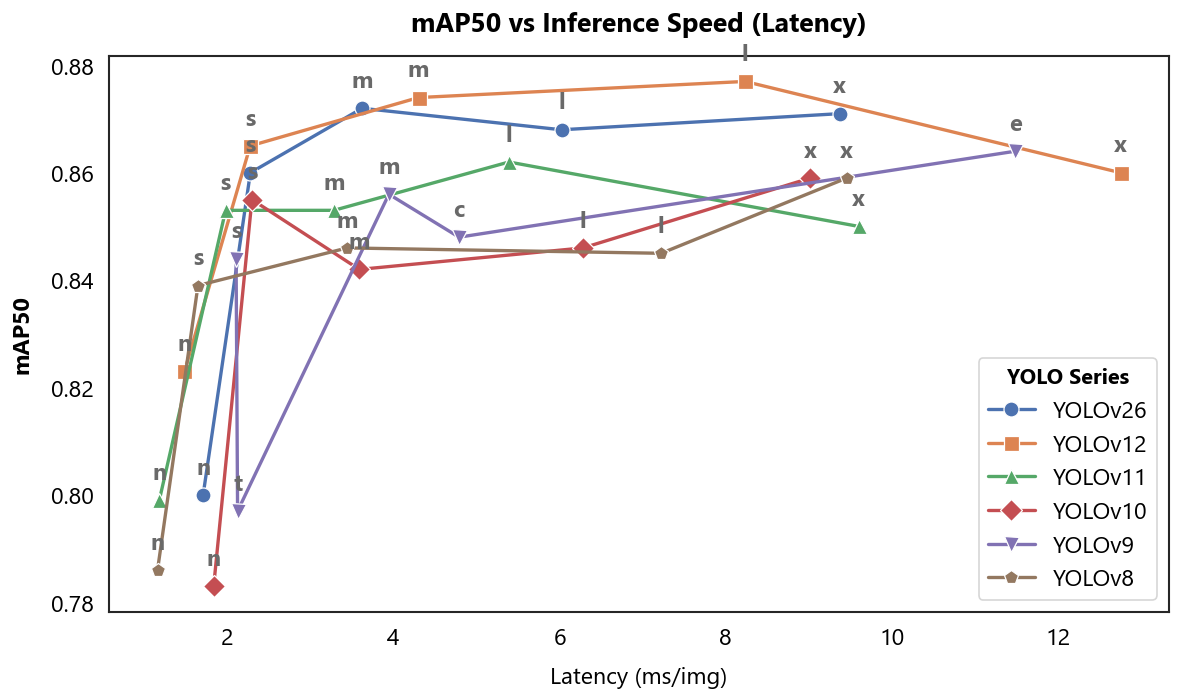

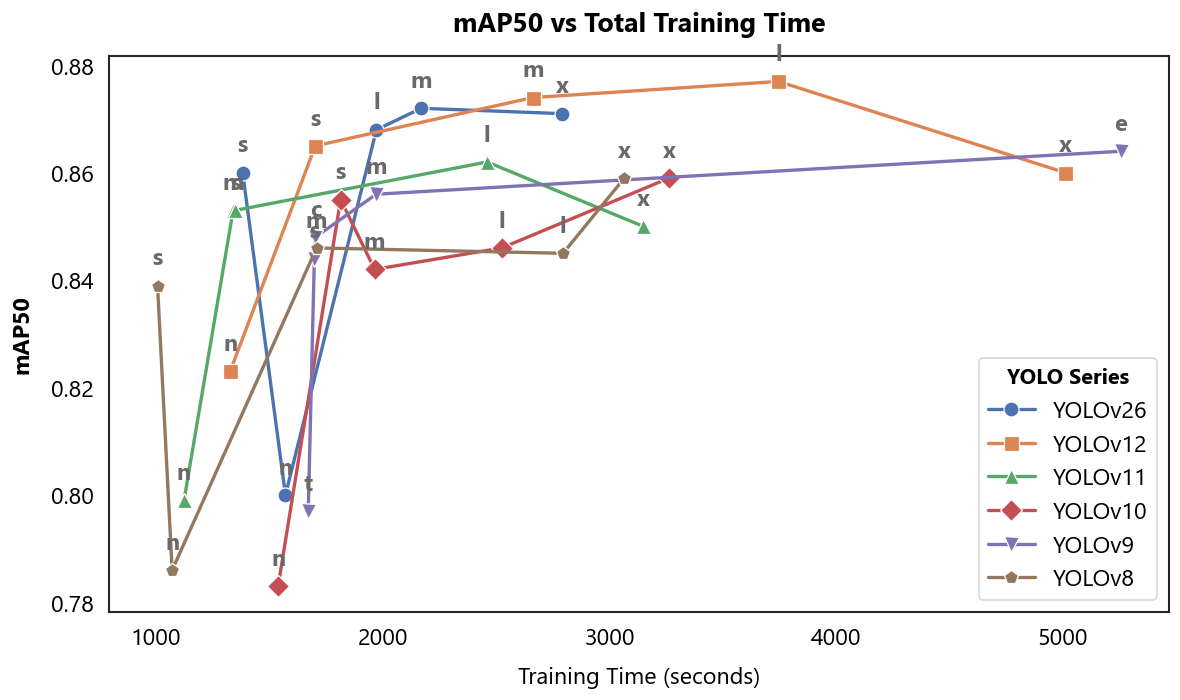

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. 파일 경로 및 FLOPs 데이터 정의
summary_csv_path = r"C:/Users/ACE_LAB_AI/Desktop/object_detection_cell/model_comparison_results/AI-Cell-Image-154_ALL_MODELS_SUMMARY.csv"

# 공식 논문/저장소 기준 정확한 FLOPs (입력 크기 640x640, 단위: GFLOPs) 반영
flops_dict = {
    "yolov8n.pt": 8.7,   "yolov8s.pt": 28.6,  "yolov8m.pt": 78.9,  "yolov8l.pt": 165.2, "yolov8x.pt": 257.8,
    "yolov9t.pt": 7.7,   "yolov9s.pt": 26.4,  "yolov9m.pt": 76.3,  "yolov9c.pt": 102.1, "yolov9e.pt": 189.0,
    "yolov10n.pt": 8.2,  "yolov10s.pt": 24.5, "yolov10m.pt": 59.1, "yolov10l.pt": 120.3, "yolov10x.pt": 160.4,
    "yolo11n.pt": 6.5,   "yolo11s.pt": 22.8,  "yolo11m.pt": 68.3,  "yolo11l.pt": 143.1, "yolo11x.pt": 220.1,
    "yolo12n.pt": 6.8,   "yolo12s.pt": 23.2,  "yolo12m.pt": 69.5,  "yolo12l.pt": 145.0, "yolo12x.pt": 224.0,
    "yolo26n.pt": 7.2,   "yolo26s.pt": 24.0,  "yolo26m.pt": 71.0,  "yolo26l.pt": 148.0, "yolo26x.pt": 230.0,
}

# 2. 데이터 로드 및 전처리
df = pd.read_csv(summary_csv_path)

# FLOPs 컬럼 추가
df['FLOPs(G)'] = df['Model'].map(flops_dict)

# 모델명 분리 및 대문자화 (yolo -> YOLOv)
def parse_model_info(model_name):
    name = model_name.replace('.pt', '')
    size = name[-1]       # 맨 마지막 글자 (n, s, m, l, x, t, c, e)
    series = name[:-1]    # 크기를 제외한 앞부분
    
    if series.startswith('yolo') and not series.startswith('yolov'):
        series = series.replace('yolo', 'YOLOv')
    elif series.startswith('yolov'):
        series = series.replace('yolov', 'YOLOv')
        
    return pd.Series([series, size])

df[['Series', 'Size']] = df['Model'].apply(parse_model_info)

# 사이즈 정렬 순서 정의
size_order = ['n', 't', 's', 'm', 'c', 'l', 'x', 'e']
df['Size'] = pd.Categorical(df['Size'], categories=size_order, ordered=True)
df = df.sort_values(by=['Series', 'Size'])

# 3. 데이터 시각화 설정
sns.set_theme(style="white")
plt.rcParams['font.family'] = 'Segoe UI'
plt.rcParams['axes.unicode_minus'] = False

# ★ 전반적인 폰트 크기 및 색상을 완전한 검정색으로 고정 설정
plt.rcParams.update({
    'font.size': 12,
    'text.color': 'black',
    'axes.labelcolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black'
})

# X축 지표와 타이틀 설정
x_metrics = {
    'FLOPs(G)': ('FLOPs (GFLOPs)', 'mAP50 vs Computation Complexity (FLOPs)'),
    'Inference_Time(ms/img)': ('Latency (ms/img)', 'mAP50 vs Inference Speed (Latency)'),
    'Train_Time(sec)': ('Training Time (seconds)', 'mAP50 vs Total Training Time')
}

# 범례 순서 (대문자에 맞춰서)
legend_order = ['YOLOv26', 'YOLOv12', 'YOLOv11', 'YOLOv10', 'YOLOv9', 'YOLOv8']

# 사용할 마커(심볼) 리스트 정의 (YOLO 시리즈 6개에 맞춰 6개의 마커 지정)
marker_list = ['o', 's', '^', 'D', 'v', 'p'] 

# 3개의 그래프를 순서대로 그리기
for x_col, (x_label, title) in x_metrics.items():
    plt.figure(figsize=(10, 6), dpi=120)
    
    # [수정된 부분] style 파라미터를 추가하고 markers에 마커 리스트를 전달
    sns.lineplot(
        data=df, 
        x=x_col, 
        y='mAP50', 
        hue='Series', 
        style='Series',          # 마커 모양을 Series에 따라 다르게 지정
        hue_order=legend_order,
        style_order=legend_order, # 마커 순서도 범례 순서와 동일하게 맞춤
        markers=marker_list,      # 각 Series별 마커 지정
        dashes=False,             # 선은 모두 실선으로 유지
        markersize=9, 
        linewidth=2,
    )
    
    # 점 옆에 n, s, m, l, x, t, c, e 텍스트 라벨 추가 (검정색, 투명도 제거)
    for i, row in df.dropna(subset=[x_col, 'mAP50']).iterrows():
        plt.text(
            row[x_col], 
            row['mAP50'] + 0.003,
            row['Size'], 
            fontsize=14, 
            ha='center', 
            va='bottom',
            weight='bold',
            color='dimgray',
            alpha=1.0
        )
        
    # 축 및 타이틀 색상 명시적 검정색 설정
    plt.title(title, fontsize=16, pad=15, weight='bold', color='black')
    plt.xlabel(x_label, fontsize=14, labelpad=10, color='black')
    plt.ylabel('mAP50', fontsize=14, labelpad=10, color='black', fontweight='bold')
    plt.xticks(fontsize=14) 
    plt.yticks(fontsize=14) 
    
    # 축의 눈금(숫자)도 검정색으로 확실하게 지정
    plt.tick_params(colors='black')
    
    # 범례 설정
    legend = plt.legend(
        title="YOLO Series", 
        loc='lower right', 
        frameon=True, 
        fontsize=14,
        title_fontsize=13
    )
    
    # 범례 제목과 항목 글씨를 완전한 검은색으로 변경
    plt.setp(legend.get_title(), color='black', weight='bold')
    for text in legend.get_texts():
        text.set_color('black')

    plt.tight_layout()
    
    save_filename = f"plot_mAP50_vs_{x_col.split('(')[0]}.png"
    plt.savefig(save_filename, dpi=300, bbox_inches='tight')
    plt.show()

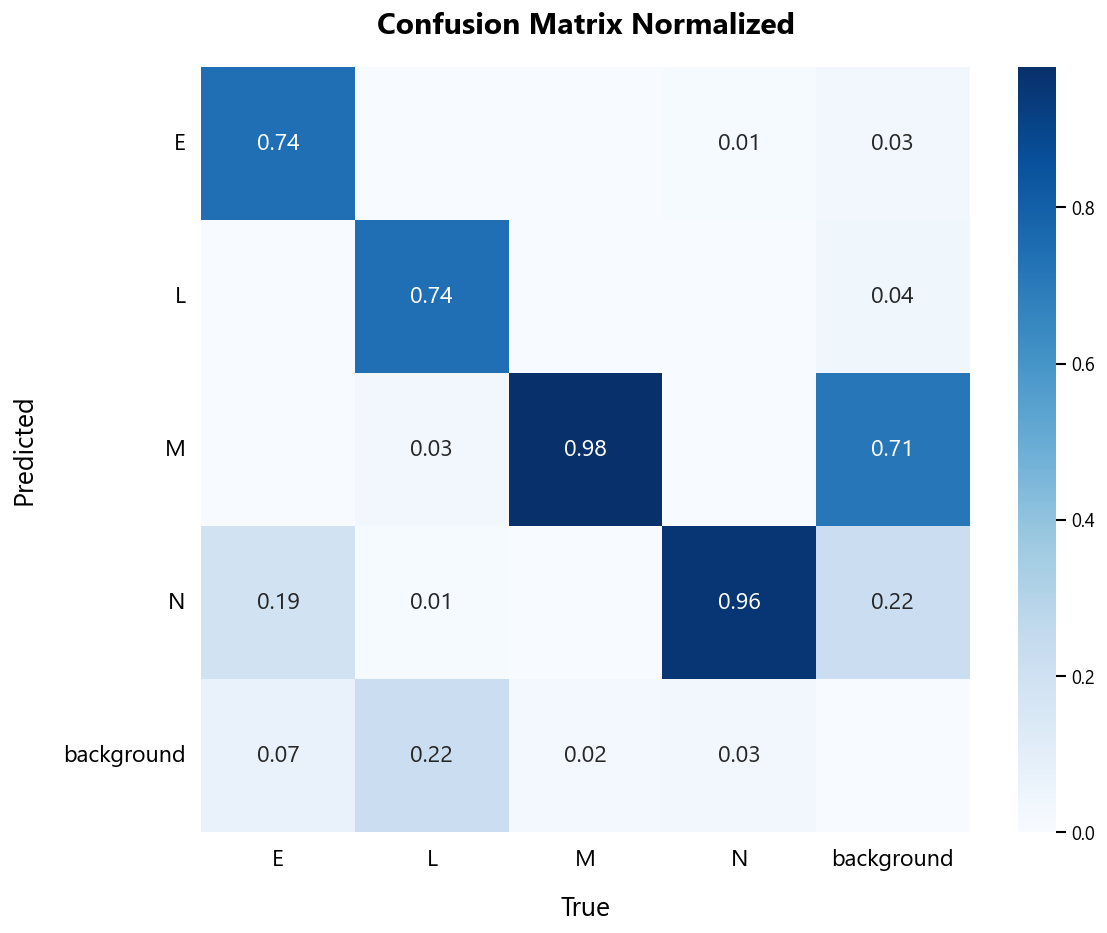

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 클래스 이름 정의
classes = ['E', 'L', 'M', 'N', 'background']

# 2. 데이터 (행: Predicted, 열: True) - image_64b04b.jpg 기준 업데이트
data = np.array([
    [0.74, 0.00, 0.00, 0.01, 0.03],
    [0.00, 0.74, 0.00, 0.00, 0.04],
    [0.00, 0.03, 0.98, 0.00, 0.71],
    [0.19, 0.01, 0.00, 0.96, 0.22],
    [0.07, 0.22, 0.02, 0.03, 0.00]
])

# 3. dtype=object로 설정하여 글자 수 짤림 현상 방지 (0인 값은 빈칸 처리)
annot_labels = np.empty(data.shape, dtype=object)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        val = data[i, j]
        if val > 0:
            annot_labels[i, j] = f"{val:.2f}"
        else:
            annot_labels[i, j] = ""

# 4. 그래프 그리기 준비
plt.figure(figsize=(10, 8), dpi=120)

# 전체적인 기본 폰트 사이즈를 14로 넉넉하게 설정
plt.rcParams.update({'font.size': 14})

# 5. Seaborn heatmap 그리기
ax = sns.heatmap(
    data, 
    annot=annot_labels,        # 커스텀 라벨(빈칸 포함) 적용
    fmt="",                    # 라벨 포맷 비활성화 (문자열 그대로 출력)
    cmap='Blues',              # 파란색 테마
    xticklabels=classes, 
    yticklabels=classes,
    cbar_kws={'shrink': 1.0},  # 컬러바 크기 비율
    annot_kws={"size": 14}     # 내부 수치 글자 크기 14로 고정
)

# 6. 축 라벨 및 타이틀 설정
plt.title('Confusion Matrix Normalized', fontsize=18, pad=20, weight='bold')
plt.xlabel('True', fontsize=16, labelpad=15)
plt.ylabel('Predicted', fontsize=16, labelpad=15)

# x축, y축 눈금 글자 크기 조정 및 y축 글씨 가로로 눕히기
plt.xticks(fontsize=14)
plt.yticks(fontsize=14, rotation=0)

plt.tight_layout()

# 고해상도 이미지로 저장
plt.savefig('confusion_matrix_recreated_updated.png', dpi=300, bbox_inches='tight')
plt.show()